# Hafta 1 · Katsayılar Anlaşamıyor, Öngörüler Anlaşıyor

**Ekonomi ve Finansta Makine Öğrenmesi** · Prof. Dr. Mehmet Songur · Dicle Üniversitesi

[![Colab'da aç](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mehmetsongur/Machine-Learning-in-Economics-and-Finance/blob/main/code/Hafta01_Katsayi_ve_Ongoru.ipynb)

**Haftanın konusu:** Yapay zekâ, makine öğrenmesi ve derin öğrenme; ekonometri ile farkı (tahmin ve nedensellik)

Bu defter, Hafta 1 ders notundaki ve slaytlarındaki şu şekil ve tabloları üretir:

- **Şekil 4:** Birbiriyle çok yüksek korelasyonlu iki değişkenle EKK; katsayı kestirimleri ve öngörü hataları (ders notu, 3.3; slayt 20)

Tüm sayılar yapay (simüle edilmiş) veriye dayanır. Rastgele sayı üreticisinin tohumu sabit olduğu için hücreler **yukarıdan aşağıya sırayla** çalıştırıldığında sonuçlar ders materyalindeki değerlerle birebir aynı çıkar. Hücreleri atlarsanız ya da sırasını değiştirirseniz sayılar biraz farklılaşabilir; yorumlar değişmez.

Slaytlar: [Hafta 1 (PDF)](https://www.songurmehmet.com/assets/dersler/ml/Hafta01_Slaytlar.pdf)  
Kod MIT lisansıyla paylaşılmıştır; ayrıntı için deponun `code/LICENSE` dosyasına bakın.

## Fikir

Hafta 1’in ana ayrımı: ekonometri çoğunlukla **β̂** (katsayıyı doğru kestirmek), makine öğrenmesi ise **ŷ** (sonucu iyi öngörmek) sorusuyla ilgilenir. Bu ayrımın neden önemli olduğunu görmek için birbirine çok benzeyen iki açıklayıcı değişken düşünelim (örneğin bir konutun metrekaresi ve oda sayısı, korelasyon ≈ 0,97). Gerçek modelde iki katsayı da 1. Bu dünyadan 100 gözlemlik 300 farklı örneklem çekip her birinde EKK ile modeli kestiriyoruz.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)   # tohum: sonuçlar ders notuyla aynı çıkar

In [2]:
R, n, rho = 300, 100, 0.97         # tekrar sayısı, gözlem sayısı, iki değişken arasındaki korelasyon
b1, b2, yhat = [], [], []

for _ in range(R):
    x1 = rng.normal(size=n)
    x2 = rho * x1 + np.sqrt(1 - rho**2) * rng.normal(size=n)
    y = 1.0 * x1 + 1.0 * x2 + rng.normal(size=n)      # gerçek katsayılar: 1 ve 1
    X = np.column_stack([np.ones(n), x1, x2])
    b = np.linalg.lstsq(X, y, rcond=None)[0]          # EKK kestirimi
    b1.append(b[1]); b2.append(b[2])
    yhat.append(b @ [1, 1, 1])                        # x1 = x2 = 1 noktasındaki öngörü (gerçek değer: 2)

b1, b2, yhat = map(np.array, (b1, b2, yhat))
print('Katsayı (β1) kestiriminin standart sapması :', b1.std().round(3))
print('Öngörünün standart sapması                :', yhat.std().round(3))
print('İki katsayı kestirimi arasındaki korelasyon:', np.corrcoef(b1, b2)[0, 1].round(3))

Katsayı (β1) kestiriminin standart sapması : 0.43
Öngörünün standart sapması                : 0.144
İki katsayı kestirimi arasındaki korelasyon: -0.971


Beklenen çıktı: katsayının standart sapması ≈ 0,43, öngörününki ≈ 0,14, iki katsayı arasındaki korelasyon ≈ −0,97. Katsayılar örneklemden örnekleme büyük ölçüde oynuyor ve birbirini telafi ediyor; öngörü ise istikrarlı.

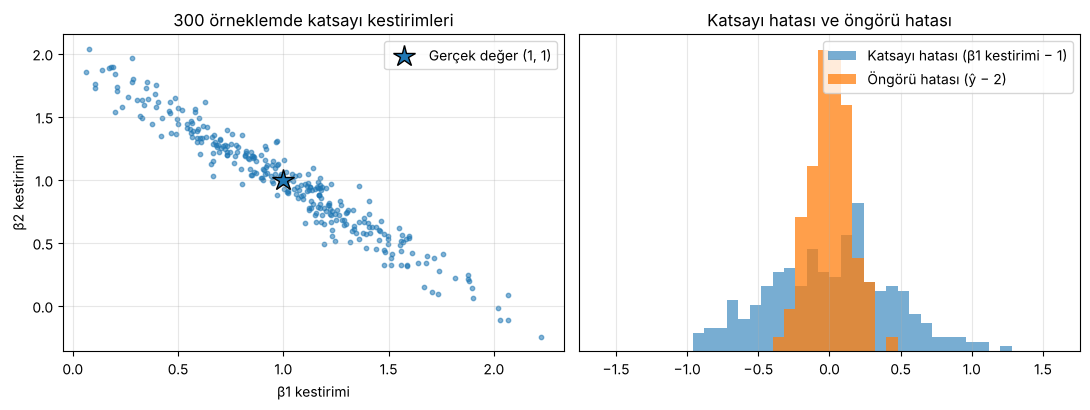

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
axs[0].scatter(b1, b2, s=10, alpha=0.55)
axs[0].plot(1, 1, '*', ms=16, mec='k', label='Gerçek değer (1, 1)')
axs[0].set(xlabel='β1 kestirimi', ylabel='β2 kestirimi', title='300 örneklemde katsayı kestirimleri')
axs[0].legend(); axs[0].grid(alpha=0.3)

bins = np.linspace(-1.6, 1.6, 41)
axs[1].hist(b1 - 1, bins=bins, alpha=0.6, label='Katsayı hatası (β1 kestirimi − 1)')
axs[1].hist(yhat - 2, bins=bins, alpha=0.75, label='Öngörü hatası (ŷ − 2)')
axs[1].set(title='Katsayı hatası ve öngörü hatası', yticks=[])
axs[1].legend(); axs[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Kendiniz deneyin

Aşağıdaki fonksiyon aynı deneyi istediğiniz korelasyonla tekrarlar. `rho` değerini 0,97’den 0,3’e düşürün: katsayılar belirgin biçimde istikrar kazanır, öngörü hatası ise çok az değişir. Çoklu doğrusal bağlantı esas olarak bir **β̂** sorunudur.

In [4]:
def deney(rho, R=300, n=100, tohum=1):
    g = np.random.default_rng(tohum)
    k, o = [], []
    for _ in range(R):
        x1 = g.normal(size=n); x2 = rho * x1 + np.sqrt(1 - rho**2) * g.normal(size=n)
        y = x1 + x2 + g.normal(size=n)
        b = np.linalg.lstsq(np.column_stack([np.ones(n), x1, x2]), y, rcond=None)[0]
        k.append(b[1]); o.append(b.sum())
    print(f'rho = {rho:4.2f}  →  katsayının std. sapması: {np.std(k):.3f}   öngörünün std. sapması: {np.std(o):.3f}')

for r in [0.97, 0.7, 0.3]:
    deney(r)

rho = 0.97  →  katsayının std. sapması: 0.456   öngörünün std. sapması: 0.130
rho = 0.70  →  katsayının std. sapması: 0.151   öngörünün std. sapması: 0.136
rho = 0.30  →  katsayının std. sapması: 0.107   öngörünün std. sapması: 0.150
